In [8]:
import pandas as pd

colors = pd.read_parquet('data/colors.parquet', engine='pyarrow')

In [9]:
colors.columns

Index(['mpc_designation', 'permid', 'provid', 'obstime_first', 'obstime_last',
       'H_u', 'H_g', 'H_r', 'H_i', 'H_z', 'H_y', 'Herr_u', 'Herr_g', 'Herr_r',
       'Herr_i', 'Herr_z', 'Herr_y', 'Hstd_u', 'Hstd_g', 'Hstd_r', 'Hstd_i',
       'Hstd_z', 'Hstd_y', 'N_u', 'N_g', 'N_r', 'N_i', 'N_z', 'N_y', 'u-g',
       'g-r', 'r-i', 'i-z', 'z-y'],
      dtype='object')

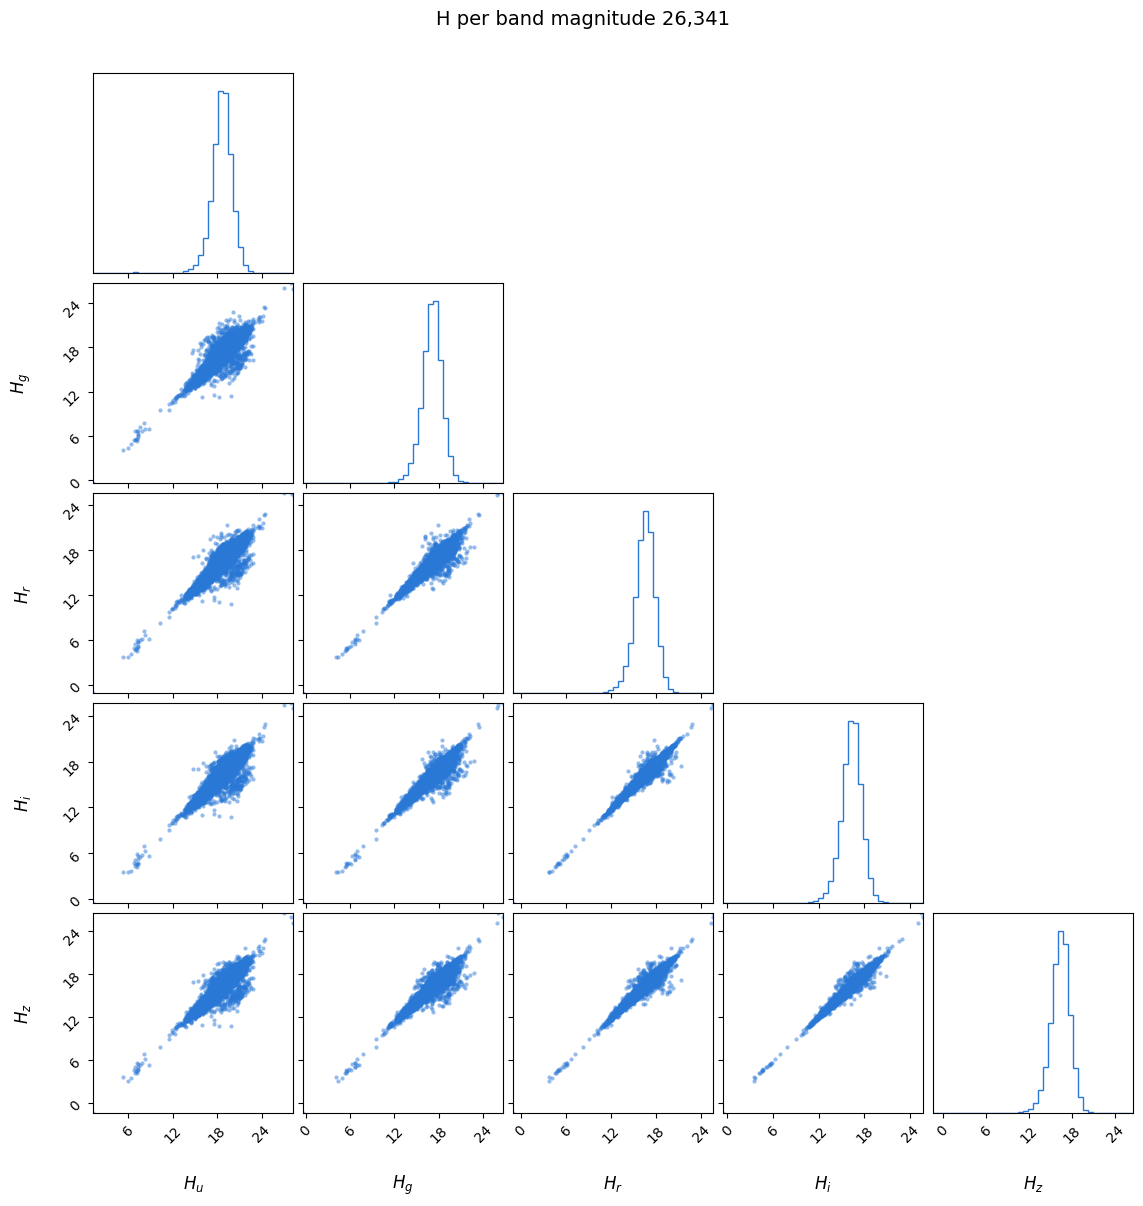

In [10]:
import corner
import matplotlib.pyplot as plt

mag_bands = colors[['H_u', 'H_g', 'H_r', 'H_i', 'H_z']].dropna().astype(float).to_numpy()

mag_labels = [r'$H_u$', r'$H_g$', r'$H_r$', r'$H_i$', r'$H_z$']
fig = corner.corner(mag_bands, labels=mag_labels, bins=40,   # each axis: central 99.5%
                    color='#2a78d6', label_kwargs=dict(fontsize=12),
                    # scatter: one point per NEO, no density contours
                    plot_datapoints=True, plot_density=False, plot_contours=False,
                    data_kwargs=dict(alpha=0.5, ms=3))
fig.suptitle(f'H per band magnitude {len(mag_bands):,}', fontsize=14, y=1.02)

# Save as PNG (bbox_inches='tight' keeps the title, which sits above the axes)
import os
os.makedirs('figures', exist_ok=True)
fig.savefig('figures/h_mag_corner_plot.png', dpi=200, bbox_inches='tight')
plt.show()

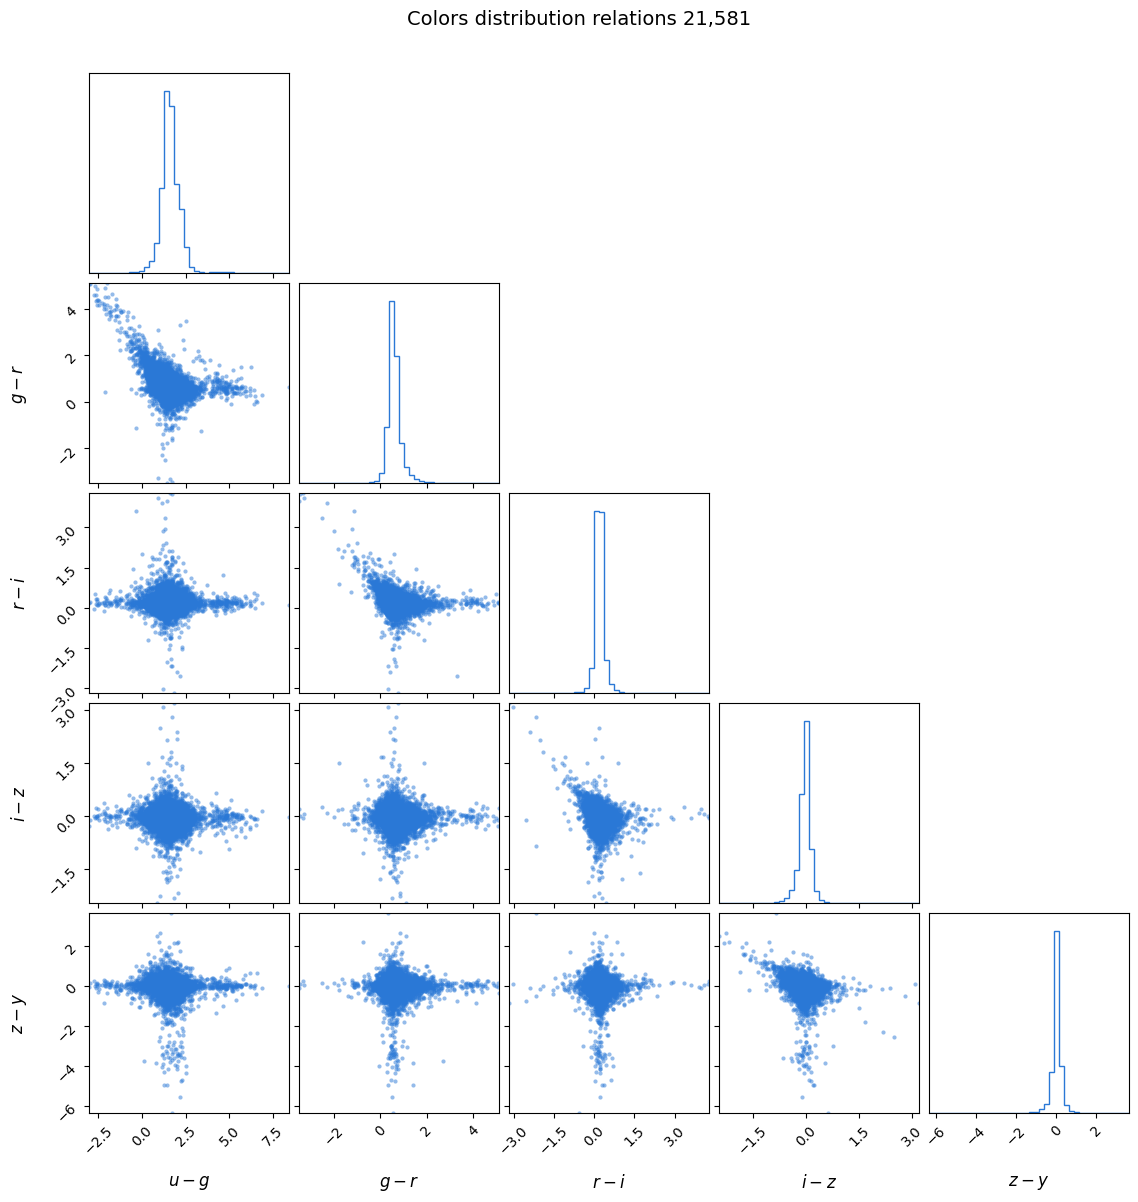

In [11]:
colors_bands = colors[['u-g', 'g-r', 'r-i', 'i-z', 'z-y']].dropna().astype(float).to_numpy()

colors_labels = [r'$u-g$', r'$g-r$', r'$r-i$', r'$i-z$', r'$z-y$']
fig = corner.corner(colors_bands, labels=colors_labels, bins=40,   # each axis: central 99.5%
                    color='#2a78d6', label_kwargs=dict(fontsize=12),
                    # scatter: one point per NEO, no density contours
                    plot_datapoints=True, plot_density=False, plot_contours=False,
                    data_kwargs=dict(alpha=0.5, ms=3))
fig.suptitle(f'Colors distribution relations {len(colors_bands):,}', fontsize=14, y=1.02)

# Save as PNG (bbox_inches='tight' keeps the title, which sits above the axes)
import os
os.makedirs('figures', exist_ok=True)
fig.savefig('figures/colors_corner_plot.png', dpi=200, bbox_inches='tight')
plt.show()

In [5]:
complete  = pd.read_csv('data/medellin-vroc-v15_10_2026.csv')

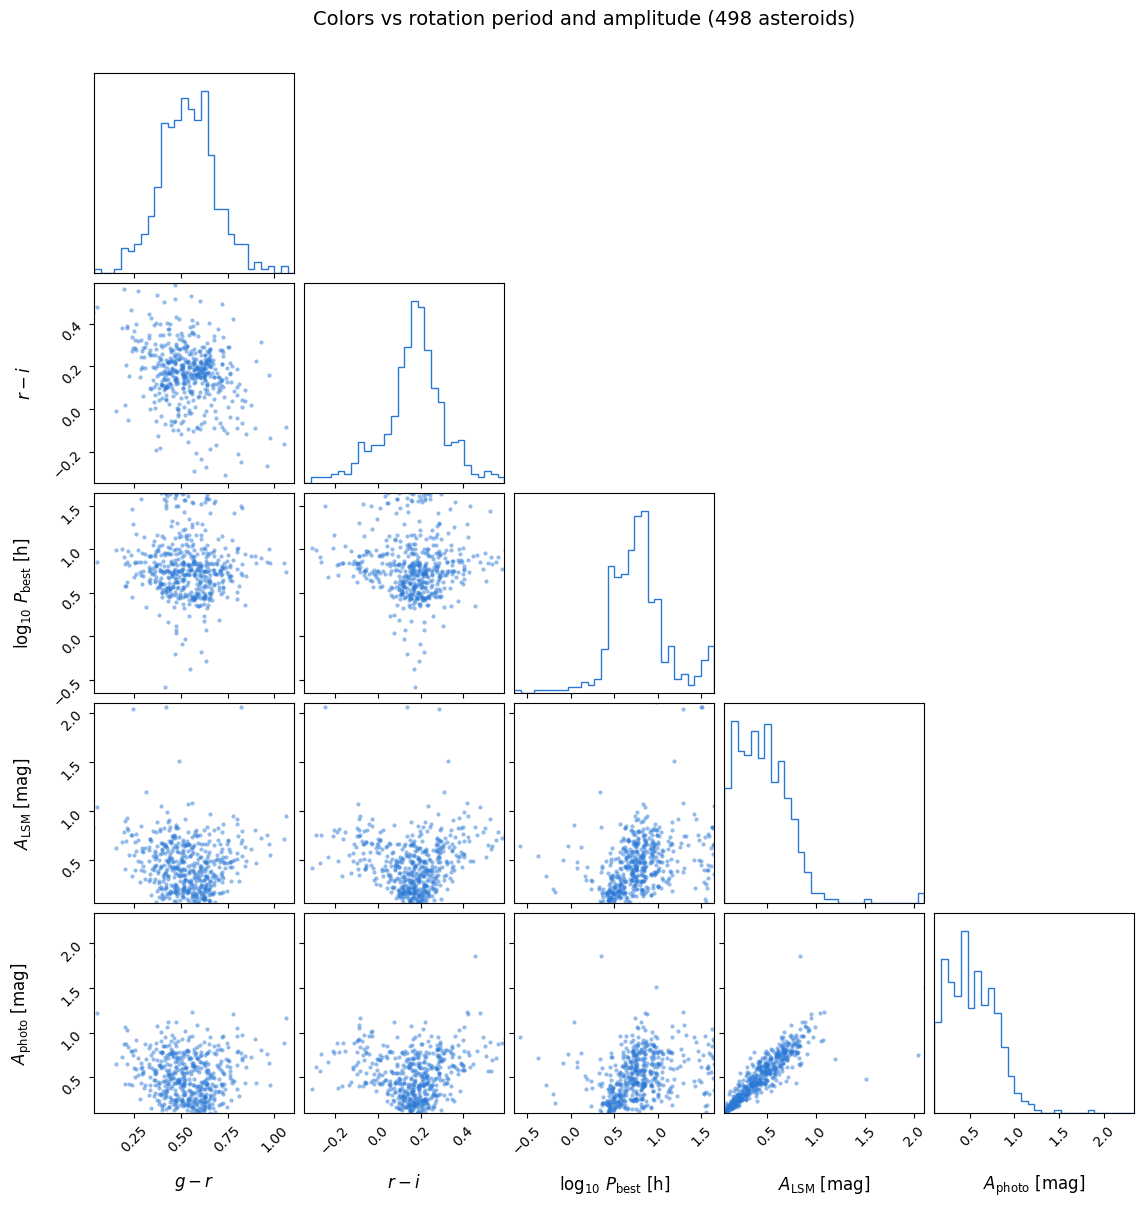

In [6]:
import numpy as np

# periods_h is a comma-separated list of candidate periods; period_best is the chosen one,
# so the plot uses period_best (log10, since periods span ~2-45 h).
# i-z is left out: only 88 of 508 objects have it.
rot = complete[['g-r', 'r-i', 'period_best', 'amp_lsm', 'amp_photo']].dropna().astype(float)
rot['log_period'] = np.log10(rot['period_best'])
rot_data = rot[['g-r', 'r-i', 'log_period', 'amp_lsm', 'amp_photo']].to_numpy()

rot_labels = [r'$g-r$', r'$r-i$', r'$\log_{10}\,P_{\rm best}$ [h]',
              r'$A_{\rm LSM}$ [mag]', r'$A_{\rm photo}$ [mag]']
fig = corner.corner(rot_data, labels=rot_labels, bins=30,
                    range=[0.995] * rot_data.shape[1],   # each axis: central 99.5%
                    color='#2a78d6', label_kwargs=dict(fontsize=12),
                    # scatter: one point per asteroid, no density contours
                    plot_datapoints=True, plot_density=False, plot_contours=False,
                    data_kwargs=dict(alpha=0.5, ms=3))
fig.suptitle(f'Colors vs rotation period and amplitude ({len(rot_data):,} asteroids)',
             fontsize=14, y=1.02)

os.makedirs('figures', exist_ok=True)
fig.savefig('figures/colors_period_amplitude_corner_plot.png', dpi=200, bbox_inches='tight')
plt.show()

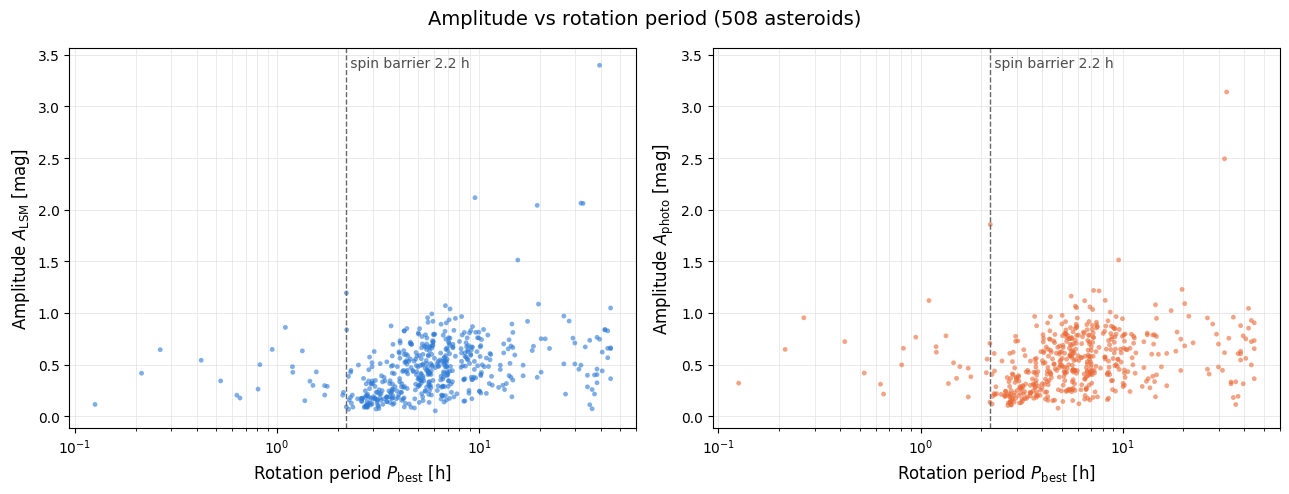

In [7]:
amp_per = complete[['period_best', 'amp_lsm', 'amp_photo']].dropna().astype(float)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
panels = [('amp_lsm', r'Amplitude $A_{\rm LSM}$ [mag]', '#2a78d6'),     # blue
          ('amp_photo', r'Amplitude $A_{\rm photo}$ [mag]', '#eb6834')]  # orange

for ax, (col, ylabel, color) in zip(axes, panels):
    ax.scatter(amp_per['period_best'], amp_per[col], s=12, alpha=0.6,
               color=color, edgecolor='none')
    # Spin barrier of rubble-pile asteroids (~2.2 h): few objects larger than ~150 m rotate faster
    ax.axvline(2.2, color='0.4', ls='--', lw=1)
    ax.text(2.2, 0.98, ' spin barrier 2.2 h', transform=ax.get_xaxis_transform(),
            va='top', ha='left', fontsize=10, color='0.3')
    ax.set_xscale('log')
    ax.set_xlabel(r'Rotation period $P_{\rm best}$ [h]', fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.tick_params(labelleft=True)   # keep y tick labels on both panels
    ax.grid(True, which='both', color='0.9', lw=0.6)
    ax.set_axisbelow(True)

fig.suptitle(f'Amplitude vs rotation period ({len(amp_per):,} asteroids)', fontsize=14)
fig.tight_layout()

os.makedirs('figures', exist_ok=True)
fig.savefig('figures/amplitude_period.png', dpi=200, bbox_inches='tight')
plt.show()